# Experiment 6: Time Series Analysis of Website Traffic

Executed notebook with output.

Detected anomalies:


,Page_Views,Z_score
2025-02-05,2003.66094,2.87361


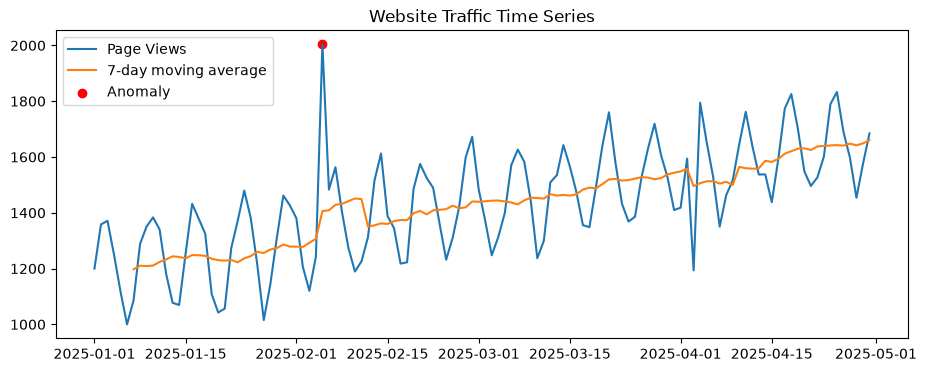

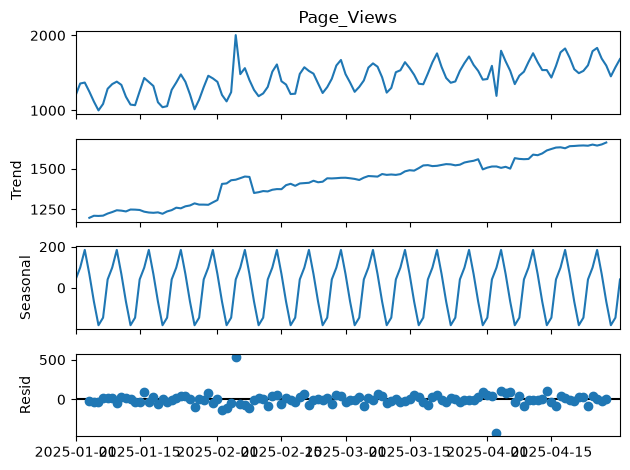

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from statsmodels.tsa.seasonal import seasonal_decompose
rng=np.random.default_rng(7); dates=pd.date_range('2025-01-01',periods=120,freq='D'); t=np.arange(120)
views=1200+4*t+180*np.sin(2*np.pi*t/7)+rng.normal(0,45,120); views[[35,92]]+=[700,-500]
df=pd.DataFrame({'Page_Views':views,'Unique_Visitors':views*.62+rng.normal(0,25,120),'Bounce_Rate':42+4*np.sin(2*np.pi*t/7)},index=dates)
df['Moving_Average']=df.Page_Views.rolling(7).mean(); df['Z_score']=(df.Page_Views-df.Page_Views.mean())/df.Page_Views.std(); anomalies=df[df.Z_score.abs()>2.5]
print('Detected anomalies:'); display(anomalies[['Page_Views','Z_score']])
plt.figure(figsize=(11,4)); plt.plot(df.index,df.Page_Views,label='Page Views'); plt.plot(df.index,df.Moving_Average,label='7-day moving average'); plt.scatter(anomalies.index,anomalies.Page_Views,c='red',label='Anomaly'); plt.legend(); plt.title('Website Traffic Time Series'); plt.show()
seasonal_decompose(df.Page_Views,model='additive',period=7).plot(); plt.tight_layout(); plt.show()